#Indice
1. [Setup](#1-Setup)
2. [Dataset](#2-Dataset)
3. [EDA](#3-EDA)
4. [Entrenamiento y Modelos de ML](#4-Modelos)


5. [Anexo](#5-Anexo)


<a name="1-Setup"></a>
# Setup


In [ ]:
from google.colab import drive
drive.mount('/content/gdrive/')
%cd /content/gdrive/MyDrive/MCTD_TFI_PROYECTO


Mounted at /content/gdrive/
/content/gdrive/.shortcut-targets-by-id/1iHIXd-ioT_0bl_zVx3rLNAELuLYREjCx/MCTD_TFI_PROYECTO


In [3]:
from pathlib import Path
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = Path('/content/drive/MyDrive/MCTD_TFI_PROYECTO')
    os.chdir(BASE_DIR)
except ImportError:
    # En local: toma la carpeta donde está el script/notebook (o el directorio actual)
    BASE_DIR = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()

# Si guardás los CSV en una subcarpeta "data" o directo en BASE_DIR:
DATA_DIR = BASE_DIR / 'data' if (BASE_DIR / 'data').exists() else BASE_DIR

print("Directorio base:", BASE_DIR)
print("Carpeta de datos:", DATA_DIR)
print("CSVs encontrados:", [f.name for f in DATA_DIR.glob('*.csv')])

Directorio base: C:\UNSa2026\entornos
Carpeta de datos: C:\UNSa2026\entornos\data
CSVs encontrados: ['dataset_combinado.csv', 'dataset_preprocesado.csv', 'validacion_produccion.csv']


In [ ]:
import sys
!{sys.executable} -m pip install numpy pandas matplotlib seaborn scikit-learn scipy xgboost

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
  Using cached cloudpickle-3.1.3-py3-none-any.whl.metadata (7.1 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

<a name="2-Dataset"></a>
# Dataset


In [ ]:
import pandas as pd

ruta_csv = DATA_DIR / 'dataset_combinado.csv'

if not ruta_csv.exists():
    raise FileNotFoundError(
        f"No se encontró '{ruta_csv}'. Descargalo desde Google Drive y ponelo en '{DATA_DIR}'."
    )

df_dengue = pd.read_csv(ruta_csv)

In [ ]:
###borrarrr
PATH_dengue = '/content/gdrive/MyDrive/MCTD_TFI_PROYECTO/dataset_combinado.csv'
df_dengue = pd.read_csv(PATH_dengue)


FileNotFoundError: [Errno 2] No such file or directory: '/content/gdrive/MyDrive/MCTD_TFI_PROYECTO/dataset_combinado.csv'

In [ ]:
df_dengue.head(n=5)

,Gender,Age,Fever_Duration,Platelet_Count,WBC_Count,Headache,Myalgia,Rash,Outcome,Fever,source
0,Female,45,2,278586,5806,0,1,0,0,False,2026
1,Male,17,1,190699,7690,1,0,0,0,False,2026
2,Female,29,1,208973,6928,0,0,0,0,False,2026
3,Female,63,7,94336,3193,0,1,0,1,True,2026
4,Male,22,1,288202,7768,0,0,0,0,False,2026


<a name="3-EDA"></a>
# EDA



*   3.1 Inspeccion
*   3.2 Graficos
*   3.3 Features vs Outcome
*   3.4 Features vs Features
*   3.5 Seleccion de caracteristicas



















<a name="3.1 Inspeccion de los datos"></a>
## 3.1 Inspeccion de los datos

Inspeccion inicial de los datos

In [ ]:
df_dengue.head(n=3)

,Gender,Age,Fever_Duration,Platelet_Count,WBC_Count,Headache,Myalgia,Rash,Outcome,Fever,source
0,Female,45,2,278586,5806,0,1,0,0,False,2026
1,Male,17,1,190699,7690,1,0,0,0,False,2026
2,Female,29,1,208973,6928,0,0,0,0,False,2026


In [ ]:
print(df_dengue.shape)
df_dengue.info()

(2018, 11)
<class 'pandas.DataFrame'>
RangeIndex: 2018 entries, 0 to 2017
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Gender          2018 non-null   str  
 1   Age             2018 non-null   int64
 2   Fever_Duration  2018 non-null   int64
 3   Platelet_Count  2018 non-null   int64
 4   WBC_Count       2018 non-null   int64
 5   Headache        2018 non-null   int64
 6   Myalgia         2018 non-null   int64
 7   Rash            2018 non-null   int64
 8   Outcome         2018 non-null   str  
 9   Fever           2018 non-null   bool 
 10  source          2018 non-null   int64
dtypes: bool(1), int64(8), str(2)
memory usage: 159.8 KB


In [ ]:
df_dengue['Outcome'].value_counts()

,count
Outcome,
Positive,697
1,533
0,467
Negative,321


In [ ]:
mapeo = {'Negative': 0, 'Positive': 1, '0':0, '1':1}
df_dengue['Outcome']=df_dengue['Outcome'].map(mapeo)


In [ ]:
df_dengue['Outcome'].value_counts()

,count
Outcome,
1,1230
0,788


In [ ]:
mapeo = {'Male': 0, 'Female': 1}
df_dengue['Gender']=df_dengue['Gender'].map(mapeo)

In [ ]:
df_dengue['Gender'].value_counts()

,count
Gender,
1,1014
0,1004


In [ ]:
mapeo = {False: 0, True: 1}
df_dengue['Fever']=df_dengue['Fever'].map(mapeo)


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Aislar primero un 15% para validación tipo producción / holdout
df_desarrollo, df_validacion_prod = train_test_split(
    df_dengue,
    test_size=0.15,
    random_state=42,
    stratify=df_dengue["Outcome"],
)
# Guardar el conjunto aislado en disco
df_validacion_prod.to_csv("validacion_produccion.csv", index=False)
df_desarrollo.shape
df_dengue=df_desarrollo

In [ ]:

df_dengue.to_csv("/content/gdrive/MyDrive/MCTD_TFI_PROYECTO/dataset_preprocesado.csv", index=False)



### Dataset preprocesado Asignacion

In [4]:
import pandas as pd

ruta_csv = DATA_DIR / 'dataset_preprocesado.csv'

if not ruta_csv.exists():
    raise FileNotFoundError(
        f"No se encontró '{ruta_csv}'. Descargalo desde Google Drive y ponelo en '{DATA_DIR}'."
    )

df_dengue = pd.read_csv(ruta_csv)

In [ ]:
## desde drive
PATH_dengue = '/content/gdrive/MyDrive/MCTD_TFI_PROYECTO/dataset_preprocesado.csv'
df_dengue = pd.read_csv(PATH_dengue)
df_dengue.shape

FileNotFoundError: [Errno 2] No such file or directory: '/content/gdrive/MyDrive/MCTD_TFI_PROYECTO/dataset_preprocesado.csv'

### Estadisticas

In [ ]:
df_dengue.describe()

,Gender,Age,Fever_Duration,Platelet_Count,WBC_Count,Headache,Myalgia,Rash,Outcome,Fever,source,cluster
count,1715.000000,1715.000000,1715.000000,1715.000000,1715.000000,1715.000000,1715.000000,1715.000000,1715.000000,1715.000000,1715.000000,1715.000000
mean,0.505539,38.237318,3.634402,158812.657143,5751.927114,0.660058,0.546939,0.426822,0.609329,0.688630,2025.490379,0.920117
std,0.500115,19.309136,2.424324,82156.018629,2762.396051,0.473827,0.497937,0.494760,0.488043,0.463189,0.500053,0.821976
min,0.000000,1.000000,0.000000,26885.000000,1740.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2025.000000,0.000000
25%,0.000000,22.000000,1.000000,88942.500000,3300.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2025.000000,0.000000
50%,1.000000,38.000000,4.000000,128210.000000,5408.000000,1.000000,1.000000,0.000000,1.000000,1.000000,2025.000000,1.000000
75%,1.000000,53.000000,6.000000,240615.000000,7156.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2026.000000,2.000000
max,1.000000,87.000000,7.000000,362426.000000,13785.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2026.000000,2.000000


In [ ]:
df_dengue.isnull().sum() # cantidad de nulos por columna

Gender            0
Age               0
Fever_Duration    0
Platelet_Count    0
WBC_Count         0
Headache          0
Myalgia           0
Rash              0
Outcome           0
Fever             0
source            0
cluster           0
dtype: int64

In [ ]:
df_dengue.duplicated().sum() # cantidad de filas completamente repetidas

np.int64(0)

In [ ]:
df_dengue.dtypes # confirma que cada columna tiene el tipo esperado

Gender            int64
Age               int64
Fever_Duration    int64
Platelet_Count    int64
WBC_Count         int64
Headache          int64
Myalgia           int64
Rash              int64
Outcome           int64
Fever             int64
source            int64
cluster           int64
dtype: object

In [ ]:
df_dengue['Outcome'].value_counts(normalize=True) # proporción dengue/no_dengue

Outcome
1    0.609329
0    0.390671
Name: proportion, dtype: float64

In [ ]:
# porcentaje de positivos en cada fuente (la media de una columna 0/1 es la proporción de 1)
df_dengue.groupby('source')['Outcome'].mean()

,Outcome
source,
2025,0.684676
2026,0.533000


In [ ]:
# promedio de las numéricas por fuente
df_dengue.groupby('source')[['Age','Platelet_Count','WBC_Count','Fever_Duration']].mean()

,Age,Platelet_Count,WBC_Count,Fever_Duration
source,,,,
2025,40.318271,165201.962672,6803.130648,4.196464
2026,35.924000,151716.703000,4696.809000,3.023000


<a name="3.2 Graficos"></a>
## 3.2 Graficos



In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

%config InlineBackend.close_figures=True

<Axes: xlabel='Outcome', ylabel='count'>

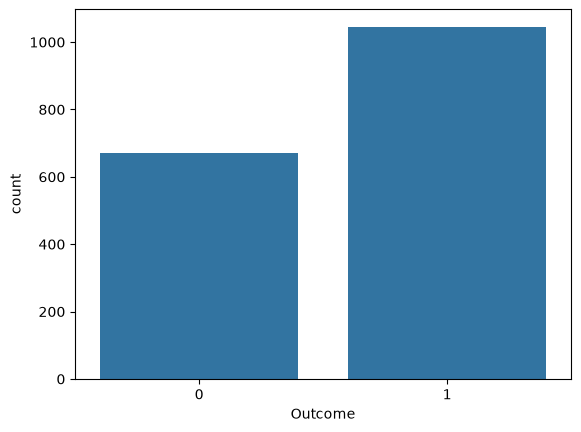

In [ ]:
sns.countplot(x='Outcome', data=df_dengue)

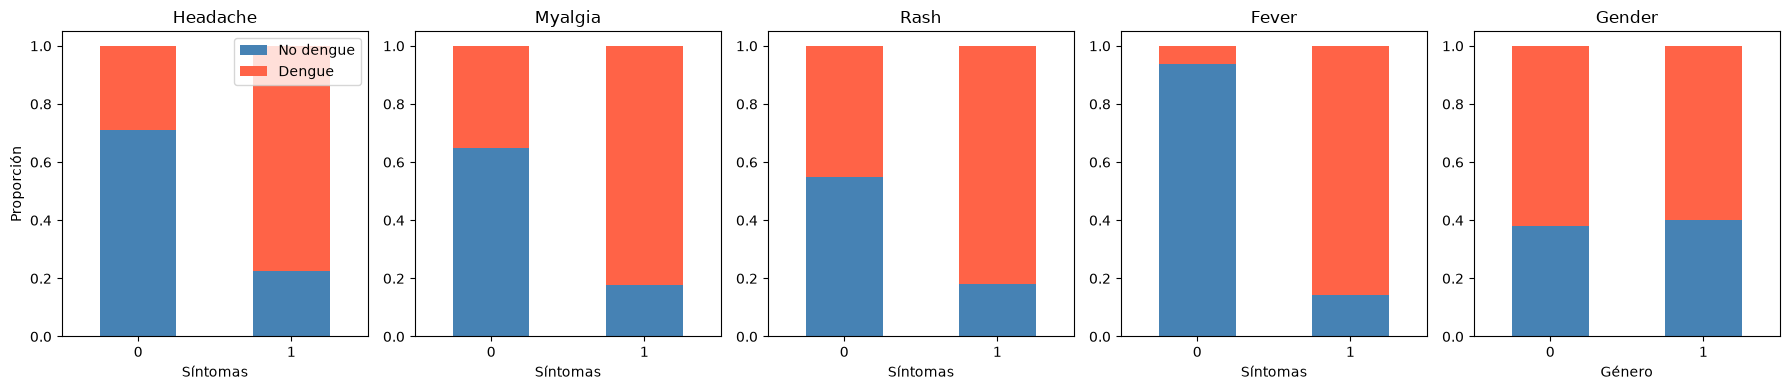

In [ ]:
vars_bin = ['Headache', 'Myalgia', 'Rash', 'Fever', 'Gender']

# Matriz de gráficos de (1,5)
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
# Agrego 4 gráficos
for ax, var in zip(axes[:4], vars_bin[:4]):
    (pd.crosstab(df_dengue[var], df_dengue['Outcome'], normalize='index')
        .plot.bar(stacked=True, ax=ax, color=['steelblue', 'tomato'], legend=False,
                  title=var, xlabel='Síntomas', rot=0))
# Agrego el gráfico 5
(pd.crosstab(df_dengue['Gender'], df_dengue['Outcome'], normalize='index')
        .plot.bar(stacked=True, ax=axes[4], color=['steelblue', 'tomato'], legend=False,
                  title='Gender', xlabel='Género', rot=0))

axes[0].set_ylabel('Proporción')
axes[0].legend(['No dengue', 'Dengue'])
plt.tight_layout()
plt.show()

<Axes: title={'center': 'Casos según si tiene o no fiebre'}, xlabel='Fiebre', ylabel='Cantidad de pacientes'>

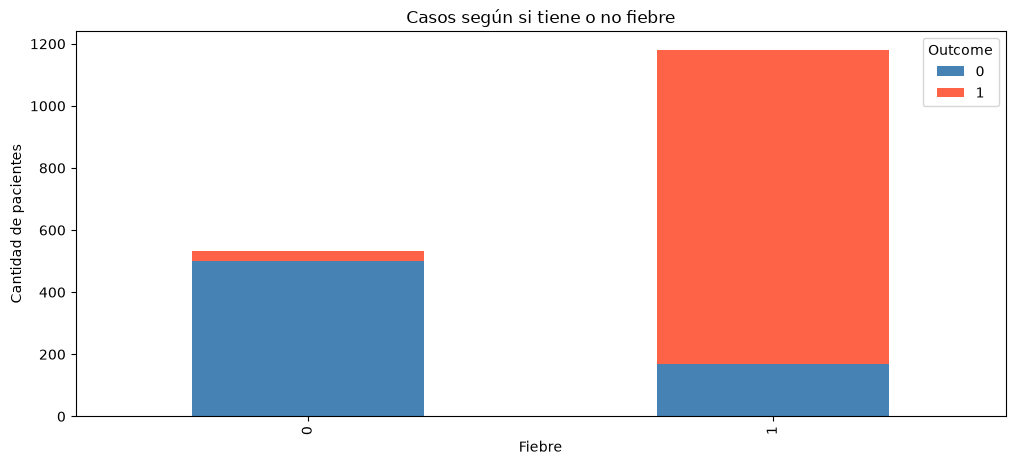

In [ ]:
(df_dengue.groupby(['Fever', 'Outcome']).size()
    .unstack(fill_value=0)
    .plot.bar(stacked=True, figsize=(12,5), color=['steelblue', 'tomato'],
              title='Casos según si tiene o no fiebre',
              ylabel='Cantidad de pacientes',
              xlabel='Fiebre'))

In [ ]:
df_dengue.groupby(['Fever', 'Outcome']).size()

Fever  Outcome
0      0           500
       1            34
1      0           170
       1          1011
dtype: int64

<Axes: title={'center': 'Casos según duración de la fiebre'}, xlabel='Duración de la fiebre (días)', ylabel='Cantidad de pacientes'>

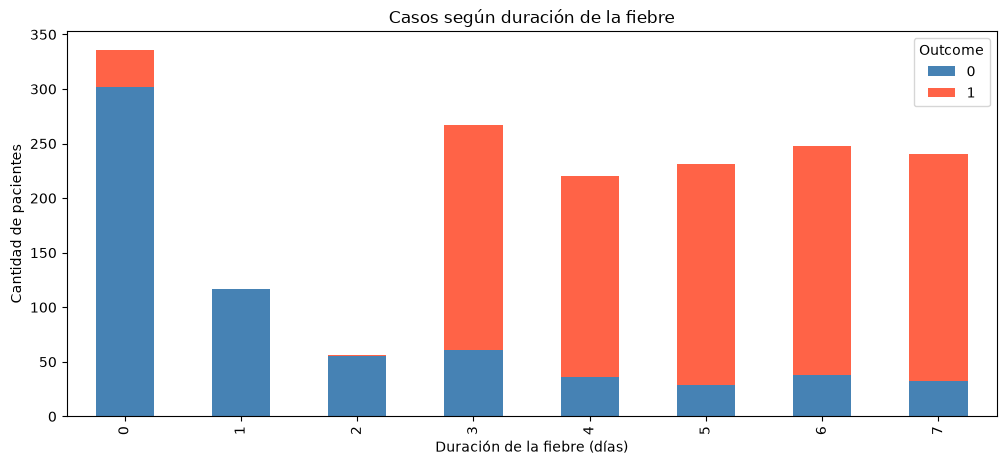

In [ ]:
(df_dengue.groupby(['Fever_Duration', 'Outcome']).size()
    .unstack(fill_value=0)
    .plot.bar(stacked=True, figsize=(12,5), color=['steelblue', 'tomato'],
              title='Casos según duración de la fiebre',
              ylabel='Cantidad de pacientes',
              xlabel='Duración de la fiebre (días)'))

Text(0.5, 1.0, 'Dispersion de duracion de la fiebre segun infectado/no infectado')

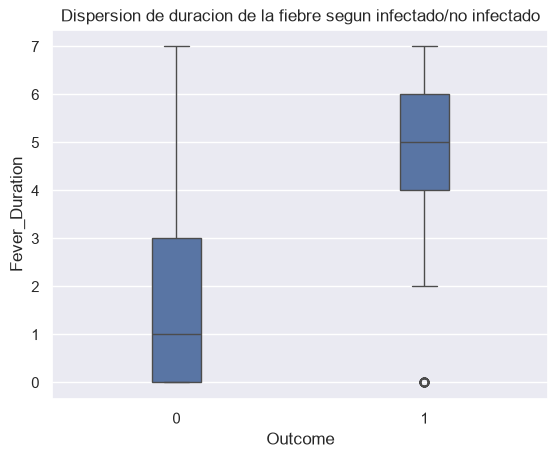

In [ ]:
sns.set()
sns.boxplot(x=df_dengue['Outcome'], y=df_dengue['Fever_Duration'], width=0.2)
plt.ylabel('Fever_Duration')
plt.title('Dispersion de duracion de la fiebre segun infectado/no infectado')

Text(0.5, 1.0, 'Dispersion de la edad segun infectado/no infectado')

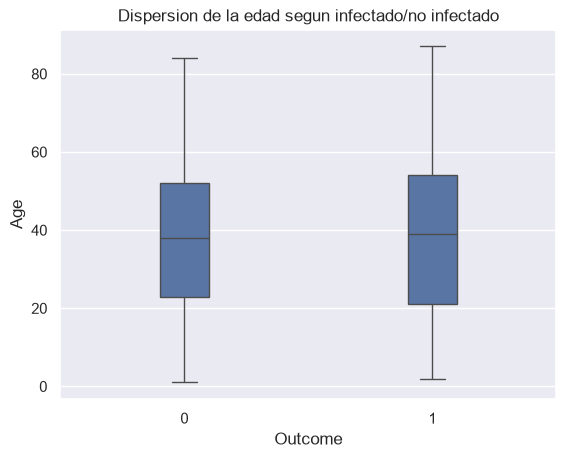

In [ ]:
sns.set()
sns.boxplot(x=df_dengue['Outcome'], y=df_dengue['Age'], width=0.2)
plt.ylabel('Age')
plt.title('Dispersion de la edad segun infectado/no infectado')

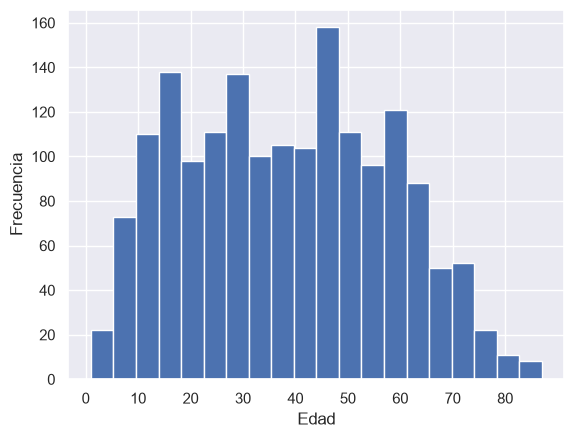

In [ ]:

n_bins=20
plt.hist(df_dengue['Age'], n_bins)
plt.ylabel('Frecuencia')
plt.xlabel('Edad')
plt.xticks(np.arange(0,90,10))
plt.show()

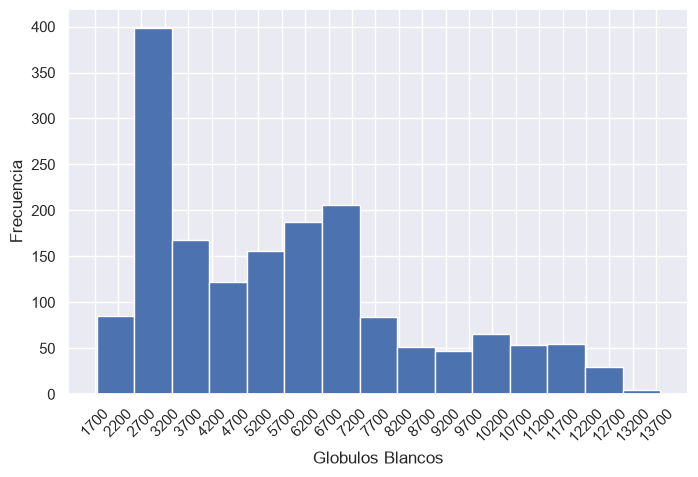

In [ ]:
n_bins=15
plt.figure(figsize=(8,5))
plt.hist(df_dengue['WBC_Count'],n_bins)
plt.xticks(np.arange(1700,14000,500))
plt.xticks(rotation=45)

plt.ylabel('Frecuencia')
plt.xlabel('Globulos Blancos')
plt.show()

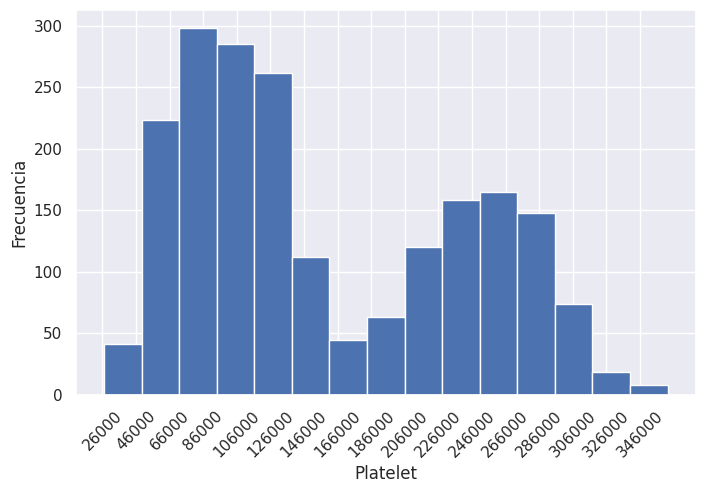

In [ ]:
n_bins=15
plt.figure(figsize=(8,5))
plt.hist(df_dengue['Platelet_Count'],n_bins)
plt.xticks(np.arange(26000,360000,20000))
plt.xticks(rotation=45)

plt.ylabel('Frecuencia')
plt.xlabel('Platelet')
plt.show()

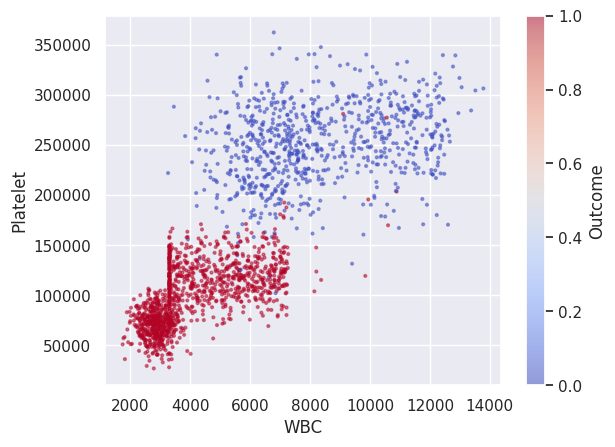

In [ ]:
df_dengue.plot.scatter(x='WBC_Count',y='Platelet_Count',s=4,c='Outcome',cmap='coolwarm',alpha=0.5)
plt.xlabel('WBC')
plt.ylabel('Platelet')
plt.show()

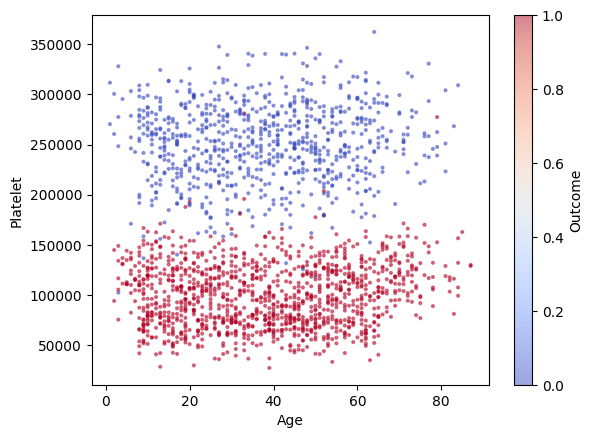

In [ ]:
df_dengue.plot.scatter(x='Age',y='Platelet_Count',s=4,c='Outcome',cmap='coolwarm',alpha=0.5)
plt.xlabel('Age')
plt.ylabel('Platelet')
plt.show()

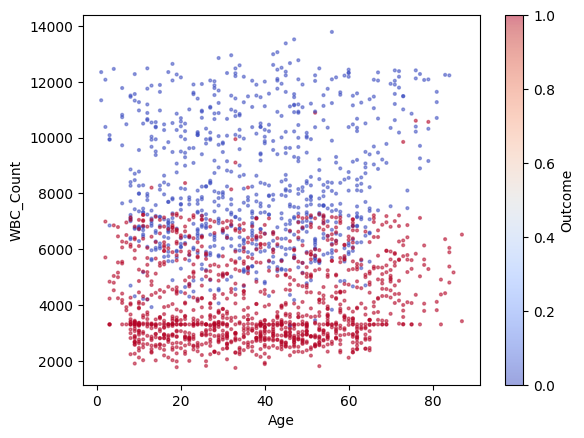

In [ ]:
df_dengue.plot.scatter(x='Age',y='WBC_Count',s=4,c='Outcome',cmap='coolwarm',alpha=0.5)
plt.xlabel('Age')
plt.ylabel('WBC_Count')
plt.show()

<a name="3.3 Relacion de features vs outcome"></a>
## 3.3 Relacion de features vs outcome


Objetivo: responder ¿qué tanto se relaciona cada variable con tener dengue? La herramienta cambia según el tipo de variable, y al final se unifican los resultados en una tabla.

#### Categoricas: Chi2

In [ ]:
from scipy.stats import chi2_contingency

In [ ]:
cols_bin = ['Gender', 'Fever', 'Headache', 'Myalgia', 'Rash']
filas = []
for c in cols_bin:
  tabla=pd.crosstab(df_dengue[c], df_dengue['Outcome'])
#pd.crosstab Compute a simple cross tabulation of two (or more) factors.By default, computes a frequency table of the factors unless an array of values and an aggregation function are passed.
  chi2, p, dof, esperadas = chi2_contingency(tabla, correction=False)
  v = np.sqrt(chi2 / tabla.values.sum())
  filas.append((c, round(p, 4), round(v, 3), esperadas.min().round(1)))

tabla_chi = pd.DataFrame(filas, columns=['variable', 'p_valor', 'cramers_v', 'min_frec_esperada'])

tabla_chi

,variable,p_valor,cramers_v,min_frec_esperada
0,Gender,0.3578,0.022,331.3
1,Fever,0.0000,0.752,208.6
2,Headache,0.0000,0.472,227.8
3,Myalgia,0.0000,0.484,303.6
4,Rash,0.0000,0.374,286.0


Cómo leerlo:

- p_valor: probabilidad de ver una asociación así si en realidad no hubiera ninguna. Menor a 0.05 sugiere asociación.
- cramers_v: qué tan fuerte es. Orientativo: < 0.1 despreciable, 0.1–0.3 débil, 0.3–0.5 moderada, > 0.5 fuerte.
- min_frec_esperada: el chi-cuadrado asume al menos 5 en cada celda esperada. Si es menor, el resultado es poco confiable.

Con muchos datos casi cualquier asociación mínima da p < 0.05. Por eso siempre se reporta el p-valor junto con Cramér's V.



---


#### Numéricas: Mann-Whitney U

---



Idea: compara la distribución de la variable entre positivos y negativos. Se usa en vez del test t porque no asume distribución normal, y variables como plaquetas o glóbulos blancos rara vez la tienen.


In [ ]:
from scipy.stats import mannwhitneyu

In [ ]:
cols_num =['Age', 'Platelet_Count', 'WBC_Count', 'Fever_Duration']
filas = []
for c in cols_num:
    pos = df_dengue.loc[df_dengue['Outcome'] == 1, c].dropna()
    neg = df_dengue.loc[df_dengue['Outcome'] == 0, c].dropna()

    u, p = mannwhitneyu(pos, neg)
    prob_sup = u / (len(pos) * len(neg))
    filas.append((c, round(p, 4), round(prob_sup, 3)))
tabla_mw = pd.DataFrame(filas, columns=['variable', 'p_valor', 'prob_superioridad'])
tabla_mw

,variable,p_valor,prob_superioridad
0,Age,0.5689,0.508
1,Platelet_Count,0.0000,0.004
2,WBC_Count,0.0000,0.059
3,Fever_Duration,0.0000,0.851


Cómo leerlo:

- prob_superioridad = probabilidad de que un positivo elegido al azar tenga un valor mayor que un negativo elegido al azar. 0.5 = sin diferencia. Cuanto más cerca de 0 o de 1, más separadas están las poblaciones. Si da, por ejemplo, 0.25, los positivos tienden a tener valores menores.

Los boxplots que se hicieron anteriormente la versión visual de este mismo análisis.



---
#### Información mutua (ranking único para todas)


---


Idea: mide cuánto se reduce la incertidumbre sobre Outcome al conocer el valor de la variable. 0 significa independencia total. Sirve para variables de cualquier tipo, así que permite ordenar las 9 en una sola lista, algo que el p-valor de un chi-cuadrado y el de un Mann-Whitney no permiten.


In [ ]:
from sklearn.feature_selection import mutual_info_classif

In [ ]:
features = cols_bin + cols_num
X = df_dengue[features]
y = df_dengue['Outcome']

# indica a sklearn cuáles columnas son discretas (binarias) y cuáles continuas
discretas = [c in cols_bin for c in features]

minfo = mutual_info_classif(X, y, discrete_features=discretas, random_state=0)
ranking_mi = pd.Series(minfo, index=features).sort_values(ascending=False)
ranking_mi

,0
Platelet_Count,0.613210
WBC_Count,0.402714
Fever,0.311510
Fever_Duration,0.291285
Myalgia,0.121299
Headache,0.112777
Rash,0.073904
Age,0.001317
Gender,0.000247


 ### Tabla resumen


---


In [ ]:
p = pd.concat([tabla_chi.set_index('variable')['p_valor'],
               tabla_mw.set_index('variable')['p_valor']])
efecto = pd.concat([tabla_chi.set_index('variable')['cramers_v'],
                    tabla_mw.set_index('variable')['prob_superioridad']])

resumen = pd.DataFrame(index=ranking_mi.index)
resumen['tipo'] = ['binaria' if c in cols_bin else 'numérica' for c in resumen.index]
resumen['info_mutua'] = ranking_mi
resumen['p_valor'] = p.map(lambda v: '<0.001' if v < 0.001 else f'{v:.3f}')
resumen['efecto'] = efecto  # V de Cramér (binarias) / prob. de superioridad (numéricas)
resumen['spearman_vs_outcome'] = df_dengue[features].corrwith(df_dengue['Outcome'], method='spearman')

resumen.round({'info_mutua': 3, 'efecto': 3, 'spearman_vs_outcome': 3})

,tipo,info_mutua,p_valor,efecto,spearman_vs_outcome
Platelet_Count,numérica,0.613,<0.001,0.004,-0.838
WBC_Count,numérica,0.403,<0.001,0.059,-0.746
Fever,binaria,0.312,<0.001,0.752,0.752
Fever_Duration,numérica,0.291,<0.001,0.851,0.599
Myalgia,binaria,0.121,<0.001,0.484,0.484
Headache,binaria,0.113,<0.001,0.472,0.472
Rash,binaria,0.074,<0.001,0.374,0.374
Age,numérica,0.001,0.569,0.508,0.014
Gender,binaria,0.000,0.358,0.022,-0.022


<a name="3.4- Relacion features vs features"></a>
## 3.4 Relacion features vs features




Objetivo: detectar variables que dicen casi lo mismo.

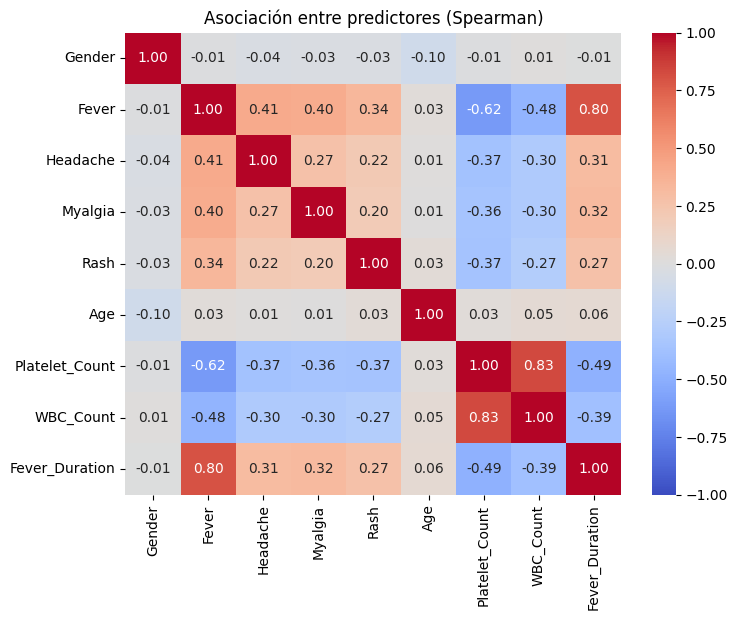

In [ ]:
# correlación de Spearman entre todos los pares de predictores
corr = df_dengue[features].corr(method='spearman')

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Asociación entre predictores (Spearman)')
plt.show()

<a name="3.5- Seleccion de caracteristicas"></a>
## 3.5 Seleccion de caracteristicas





Con 9 atributos no hay un problema de alta dimensión. La selección de características acá sirve para entender qué variables se relacionan con el dengue y para justificar un modelo simple, no para combatir el overfitting por exceso de columnas.

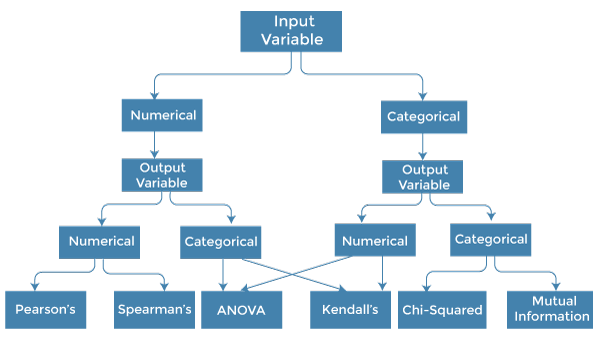

In [ ]:
features = ['Gender', 'Age', 'Fever_Duration', 'Platelet_Count', 'WBC_Count',
       'Headache', 'Myalgia', 'Rash', 'Outcome', 'Fever']
print(features)

['Gender', 'Age', 'Fever_Duration', 'Platelet_Count', 'WBC_Count', 'Headache', 'Myalgia', 'Rash', 'Outcome', 'Fever']


In [ ]:
X = df_dengue.iloc[:, [0,1,2,5,6,7,9]]
y = df_dengue.iloc[:, [8]]
print(X.head())
print(y.head())

   Gender  Age  Fever_Duration  Headache  Myalgia  Rash  Fever
0       0   10               4         1        1     0      1
1       1   47               6         0        0     1      1
2       1   47               5         1        1     1      1
3       0   34               3         1        0     0      0
4       0   50               0         0        0     0      0
   Outcome
0        1
1        1
2        0
3        0
4        0


### **Selección de características basadas en Filtro: SelectKBest chi2**

In [ ]:
from sklearn import preprocessing
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import chi2

In [ ]:
# Defino feature selection
k=4
fs = SelectKBest(score_func=chi2, k=k)

# Aplico feature selection
X_selected = fs.fit_transform(X, y)


print(X[:5])
print(X_selected.shape)
print(X_selected[:5])

   Gender  Age  Fever_Duration  Headache  Myalgia  Rash  Fever
0       0   10               4         1        1     0      1
1       1   47               6         0        0     1      1
2       1   47               5         1        1     1      1
3       0   34               3         1        0     0      0
4       0   50               0         0        0     0      0
(1715, 4)
[[4 1 0 1]
 [6 0 1 1]
 [5 1 1 1]
 [3 0 0 0]
 [0 0 0 0]]


### **Selección de Características Envolvente:**

Las técnicas de selección envolventes crean muchos modelos usando diferentes subconjuntos de features (de entrada) para luego elegir aquel subconjunto que genere el mejor modelo según métricas de performance. RFE es una técnica envolvente conocida.

In [ ]:
#librerias
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

In [ ]:
from sklearn.feature_selection import RFE
from sklearn.tree import DecisionTreeClassifier

### **RFE**

In [ ]:
# defino rfe
n_features_to_select=4
rfe = RFE(estimator=DecisionTreeClassifier(), n_features_to_select=n_features_to_select)

# entreno el modelo
rfe.fit(X,y)
print(X.head())
for i in range(X.shape[1]):
 print('columna: %d, elegida? %s, Ranking importancia: %.3f' % (i, rfe.support_[i], rfe.ranking_[i]))


   Gender  Age  Fever_Duration  Headache  Myalgia  Rash  Fever
0       0   10               4         1        1     0      1
1       1   47               6         0        0     1      1
2       1   47               5         1        1     1      1
3       0   34               3         1        0     0      0
4       0   50               0         0        0     0      0
columna: 0, elegida? False, Ranking importancia: 2.000
columna: 1, elegida? True, Ranking importancia: 1.000
columna: 2, elegida? True, Ranking importancia: 1.000
columna: 3, elegida? False, Ranking importancia: 3.000
columna: 4, elegida? True, Ranking importancia: 1.000
columna: 5, elegida? False, Ranking importancia: 4.000
columna: 6, elegida? True, Ranking importancia: 1.000


In [ ]:


g_importances = pd.Series(rfe.feature_importances_, index = X.columns)
g_importances.sort_values(ascending=True, inplace=True)
g_importances.plot.barh()
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('RF - Feature Importance')

### **RFECV**

In [ ]:
rfe = RFECV(LogisticRegression(max_iter=1000), cv=5, scoring='f1')
rfe.fit(X_esc, y)

dict(zip(features, rfe.support_))   # True = variable seleccionada
print(rfe.n_features_)              # cantidad óptima de variables

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for exam

4


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for exam

### **Métodos embebidos**

#### **LASSO**

C controla la fuerza de la penalización: valores chicos eliminan más variables. Probaremos con (0.1, 0.5, 1) y comprobaremos si el conjunto de variables que sobrevive es estable.

In [ ]:
X_esc = StandardScaler().fit_transform(X)   # L1 es sensible a la escala

for x in [0.1,0.5,1]:
  l1 = LogisticRegression(penalty='l1', solver='liblinear', C=x, max_iter=1000)
  l1.fit(X_esc, y)
  print(pd.Series(l1.coef_[0], index=X.columns).sort_values(key=abs, ascending=False))

Fever             1.738193
Myalgia           0.775262
Headache          0.673669
Rash              0.482875
Fever_Duration    0.000000
Gender            0.000000
Age               0.000000
dtype: float64
Fever             1.811208
Myalgia           0.847893
Headache          0.734531
Rash              0.548715
Age              -0.015479
Fever_Duration    0.000000
Gender            0.000000
dtype: float64
Fever             1.844377
Myalgia           0.858062
Headache          0.742437
Rash              0.557814
Fever_Duration   -0.025620
Age              -0.021621
Gender           -0.002056
dtype: float64


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


#### **Features Importances**

Ciertas técnicas de ML poseen una característica interno que les permite seleccionar los mejores atributos para usar en los modelos.

In [ ]:
import sklearn
from sklearn.model_selection import train_test_split,TunedThresholdClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

# Tuneo de Hiperparámetros
from sklearn.model_selection import RepeatedStratifiedKFold, GridSearchCV,RepeatedKFold


from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay, roc_auc_score, make_scorer, fbeta_score


In [ ]:
numericas = ['Fever_Duration','Age']
binarias = ['Gender', 'Headache', 'Myalgia', 'Rash', 'Fever']

sc = StandardScaler()
X = df_dengue[numericas + binarias].copy()
# Escalamos las columnas numéricas usando sus nombres correctos en lugar de índices de posición
X[numericas] = sc.fit_transform(X[numericas])
y = df_dengue['Outcome']
print(X)


      Fever_Duration       Age  Gender  Headache  Myalgia  Rash  Fever
0           0.150848 -1.462808       0         1        1     0      1
1           0.976061  0.453943       1         0        0     1      1
2           0.563454  0.453943       1         1        1     1      1
3          -0.261759 -0.219510       0         1        0     0      0
4          -1.499578  0.609355       0         0        0     0      0
...              ...       ...     ...       ...      ...   ...    ...
1710        0.150848 -1.825436       1         1        1     0      1
1711        0.976061 -1.307396       0         1        1     0      1
1712        0.976061 -0.789355       0         1        1     1      1
1713        1.388667  0.557551       1         1        1     1      1
1714        0.563454  0.350334       0         1        1     1      1

[1715 rows x 7 columns]


In [ ]:
## Split del dataset

test_size = 0.25
X_train, X_test, y_train, y_test = sklearn.model_selection.train_test_split(X, y, test_size = test_size, random_state = 5)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(1286, 7)
(429, 7)
(1286,)
(429,)


Text(0.5, 1.0, 'RF - Feature Importance')

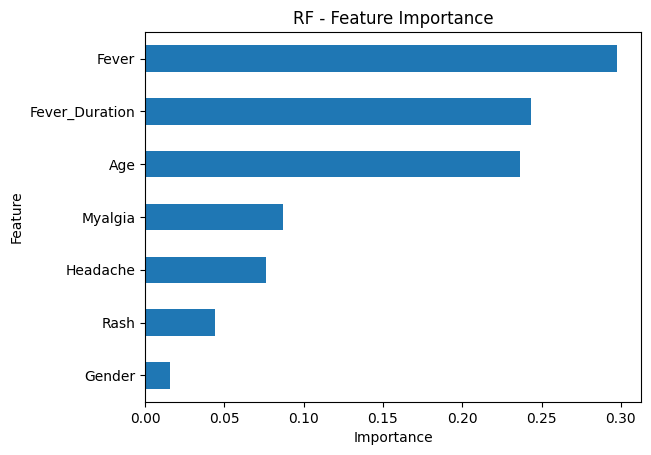

In [ ]:
modelo_RF = RandomForestClassifier(n_estimators=100, random_state=42)
modelo_RF.fit(X_train, y_train)

g_importances = pd.Series(modelo_RF.feature_importances_, index = X_train.columns)
g_importances.sort_values(ascending=True, inplace=True)
g_importances.plot.barh()
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('RF - Feature Importance')

<a name="4-Modelos"></a>
# Modelos ML







In [ ]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 44.0 MB/s  0:00:02


In [7]:
# Preprocesamiento
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Modelos
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from catboost import CatBoostClassifier
from xgboost import XGBClassifier

# Métricas
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay, roc_auc_score, make_scorer, fbeta_score

# Tuneo de Hiperparámetros y umbral
from sklearn.model_selection import RepeatedStratifiedKFold, GridSearchCV,RepeatedKFold
from sklearn.model_selection import train_test_split, TunedThresholdClassifierCV

#### Dataset

In [ ]:
PATH_dengue = '/content/gdrive/MyDrive/MCTD_TFI_PROYECTO/dataset_preprocesado.csv'
df_dengue = pd.read_csv(PATH_dengue)

In [5]:
import pandas as pd

ruta_csv = DATA_DIR / 'dataset_preprocesado.csv'

if not ruta_csv.exists():
    raise FileNotFoundError(
        f"No se encontró '{ruta_csv}'. Descargalo desde Google Drive y ponelo en '{DATA_DIR}'."
    )

df_dengue = pd.read_csv(ruta_csv)

In [8]:
numericas = [ 'Fever_Duration','Age']#,'Platelet_Count','WBC_Count']
binarias = ['Headache', 'Myalgia', 'Rash', 'Fever']

X = df_dengue[numericas + binarias]
y = df_dengue['Outcome']

preprocesador = ColumnTransformer(
    transformers=[('escalado', StandardScaler(), numericas)],
    remainder='passthrough'  # las binarias pasan sin cambios
)

In [9]:
df_dengue.shape

(1715, 12)

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

### Regresión Logística

Logistic Regression
A favor:

*   Simple, rápido de entrenar y de predecir.
*   Altamente interpretable: los coeficientes indican el efecto de cada atributo (odds ratios).
*   Devuelve probabilidades calibradas de pertenencia a cada clase.
*   Poco propenso a overfitting en datasets pequeños o medianos, y se puede regularizar (L1/L2).
*   Bajo consumo de memoria y CPU; escala bien a datasets grandes.

En contra:

*   Asume relación lineal entre los atributos y el log-odds de la salida; no captura relaciones complejas o no lineales sin ingeniería de atributos.
*   Requiere normalización/escalado de los datos y codificación de variables categóricas.
*   No maneja missing values de forma nativa.








#### Regresión logística con datos de laboratorio

In [ ]:
modelo = LogisticRegression(max_iter=5000)
modelo.fit(X_train, y_train)          # ajusta el scaler solo con train y entrena

pred_train = modelo.predict(X_train)
pred_test = modelo.predict(X_test)

y_pred = modelo.predict_proba(X_test)[:,1]
print("Test ROC_AUC",roc_auc_score(y_test, y_pred))

print('Train Accuracy: {:.4f}'.format(accuracy_score(y_train, pred_train)))
print('Tasa de Error: {:.4f}'.format(1 - accuracy_score(y_train, pred_train)))

print('Test Accuracy: {:.4f}'.format(accuracy_score(y_test, pred_test)))
print('Tasa de Error: {:.4f}'.format(1 - accuracy_score(y_test, pred_test)))

print(classification_report(y_test, pred_test,digits=4))


Test ROC_AUC 0.9998175515416895
Train Accuracy: 0.9907
Tasa de Error: 0.0093
Test Accuracy: 0.9883
Tasa de Error: 0.0117
              precision    recall  f1-score   support

           0     0.9766    0.9940    0.9853       168
           1     0.9961    0.9847    0.9904       261

    accuracy                         0.9883       429
   macro avg     0.9864    0.9894    0.9878       429
weighted avg     0.9885    0.9883    0.9884       429



In [ ]:
pipe = Pipeline([
    ('prep', preprocesador),
    ('modelo', LogisticRegression(solver='liblinear', max_iter=5000))
])

# Prueba
base = TunedThresholdClassifierCV(pipe, scoring='f1', cv=5)

K = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=1)

paramGrid = {
    #'modelo__class_weight': [None, {0: 1, 1: 2}]
    'estimator__modelo__penalty': ['l1', 'l2'],
    'estimator__modelo__C': [0.001, 0.01, 0.1, 1, 10, 100]
}

scoring = {'f2': make_scorer(fbeta_score, beta=2),'recall': 'recall', 'precision': 'precision', 'f1': 'f1'}

modelo = GridSearchCV(base, paramGrid, cv=K, scoring=scoring,
                      refit='f1', n_jobs=-1, verbose=1)

modelo.fit(X_train, y_train)          # ajusta el scaler solo con train y entrena

pred_train = modelo.predict(X_train)
pred_test = modelo.predict(X_test)

print("Mejores hiperparámetros:", modelo.best_params_)
i = modelo.best_index_
for m in scoring:
    media = modelo.cv_results_[f'mean_test_{m}'][i]
    desvio = modelo.cv_results_[f'std_test_{m}'][i]
    print(f"CV {m}: {media:.4f} ± {desvio:.4f}")

print("Umbral óptimo:", modelo.best_estimator_.best_threshold_)

y_pred = modelo.predict_proba(X_test)[:,1]
print("Test ROC_AUC",roc_auc_score(y_test, y_pred))

print('Train Accuracy: {:.4f}'.format(accuracy_score(y_train, pred_train)))
print('Tasa de Error: {:.4f}'.format(1 - accuracy_score(y_train, pred_train)))

print('Test Accuracy: {:.4f}'.format(accuracy_score(y_test, pred_test)))
print('Tasa de Error: {:.4f}'.format(1 - accuracy_score(y_test, pred_test)))

print(classification_report(y_test, pred_test,digits=4))

#Train Accuracy: 0.99
#Tasa de Error: 0.01
#Test Accuracy: 1.00
#Tasa de Error: 0.00
#              precision    recall  f1-score   support

#           0       1.00      0.99      0.99       158
#           1       0.99      1.00      1.00       246

#    accuracy                           1.00       404
#   macro avg       1.00      0.99      0.99       404
#weighted avg       1.00      1.00      1.00       404

Fitting 15 folds for each of 12 candidates, totalling 180 fits


C:\UNSa2026\entornos\entorno2\Lib\site-packages\sklearn\model_selection\_validation.py:493: FitFailedWarning: 
15 fits failed out of a total of 180.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
15 fits failed with the following error:
Traceback (most recent call last):
  File "C:\UNSa2026\entornos\entorno2\Lib\site-packages\sklearn\model_selection\_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\UNSa2026\entornos\entorno2\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\UNSa2026\entornos\entorno2\Lib\site-packages\sklearn\model_selection\_classification_thresho

Mejores hiperparámetros: {'estimator__modelo__C': 1, 'estimator__modelo__penalty': 'l1'}
CV f2: 0.9354 ± 0.0126
CV recall: 0.9511 ± 0.0137
CV precision: 0.8780 ± 0.0197
CV f1: 0.9129 ± 0.0137
Umbral óptimo: 0.5385895174919786
Test ROC_AUC 0.950579273855136
Train Accuracy: 0.8904
Tasa de Error: 0.1096
Test Accuracy: 0.9021
Tasa de Error: 0.0979
              precision    recall  f1-score   support

           0     0.9038    0.8393    0.8704       168
           1     0.9011    0.9425    0.9213       261

    accuracy                         0.9021       429
   macro avg     0.9025    0.8909    0.8959       429
weighted avg     0.9022    0.9021    0.9014       429



C:\UNSa2026\entornos\entorno2\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\UNSa2026\entornos\entorno2\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


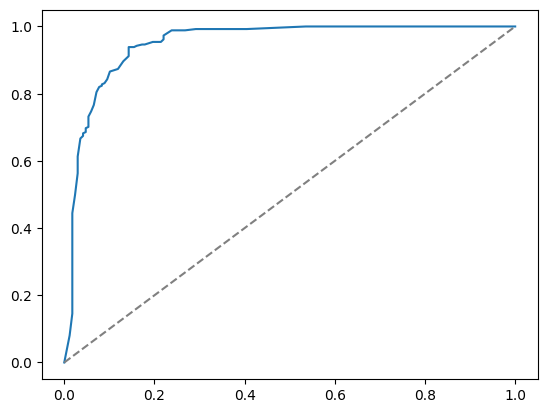

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_proba = modelo.predict_proba(X_test)[:,1]
fpr, tpr, umbrales = roc_curve(y_test,y_proba)
auc = roc_auc_score(y_test, y_proba)

plt.plot(fpr, tpr, label=f'AUC={auc:.3f}')
plt.plot([0,1],[0,1],linestyle='--', color='gray',label='Azar')
plt.show()

### Random Forest



A favor:
* Obtiene buenos resultados para diferentes tipos de problemas
* Es capaz de modelar relaciones complejas y no lineales entre los atributos de entrada y salida
* Maneja diferentes tipos de datos incluyendo variables numéricas y categóricas
* Puede manejar datasets de gran tamaño y cardinalidad

En contra:
*   Puede requerir mucha memoria y CPU en datasets grandes
*   Es sensible a outliers



In [ ]:
# Creacion, entrenamiento y evaluación del Modelo

pipe = Pipeline([
    ('prep', preprocesador),
    ('modelo', RandomForestClassifier(random_state=1)) # class_weight='balanced'
])

base = TunedThresholdClassifierCV(pipe, scoring='f1', cv=5)

K = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=1)

paramGrid = {
    'estimator__modelo__n_estimators': [200, 500],
    'estimator__modelo__max_depth': [3, 5, 7, 10, None],
    'estimator__modelo__min_samples_leaf': [1, 3, 5],
    'estimator__modelo__max_features': ['sqrt', 0.5]
    #,'estimator__modelo__class_weight': [None, {0: 1, 1: 2}]
}
scoring = {'f2': make_scorer(fbeta_score, beta=2),'recall': 'recall', 'precision': 'precision', 'f1': 'f1'}

modelo = GridSearchCV(
    base,
    paramGrid, cv=K, scoring=scoring, refit='f1', n_jobs=-1, verbose=1
)

modelo.fit(X_train, y_train)

print("Mejores hiperparámetros:", modelo.best_params_)
i = modelo.best_index_
for m in scoring:
    media = modelo.cv_results_[f'mean_test_{m}'][i]
    desvio = modelo.cv_results_[f'std_test_{m}'][i]
    print(f"CV {m}: {media:.4f} ± {desvio:.4f}")

print("Umbral óptimo:", modelo.best_estimator_.best_threshold_)

pred_train = modelo.predict(X_train)
pred_test = modelo.predict(X_test)

# prediction
y_pred = modelo.predict_proba(X_test)[:,1]
print("Test ROC_AUC",roc_auc_score(y_test, y_pred))

print('Train Accuracy: {:.4f}'.format(accuracy_score(y_train, pred_train)))
print('Tasa de Error: {:.4f}'.format(1 - accuracy_score(y_train, pred_train)))

print('Test Accuracy: {:.4f}'.format(accuracy_score(y_test, pred_test)))
print('Tasa de Error: {:.4f}'.format(1 - accuracy_score(y_test, pred_test)))

print(classification_report(y_test, pred_test,digits=4))

Fitting 15 folds for each of 60 candidates, totalling 900 fits
Mejores hiperparámetros: {'estimator__modelo__max_depth': 5, 'estimator__modelo__max_features': 0.5, 'estimator__modelo__min_samples_leaf': 1, 'estimator__modelo__n_estimators': 500}
CV f2: 0.9365 ± 0.0145
CV recall: 0.9519 ± 0.0154
CV precision: 0.8797 ± 0.0194
CV f1: 0.9143 ± 0.0151
Umbral óptimo: 0.568555725956221
Test ROC_AUC 0.9538861521620142
Train Accuracy: 0.8997
Tasa de Error: 0.1003
Test Accuracy: 0.9044
Tasa de Error: 0.0956
              precision    recall  f1-score   support

           0     0.9045    0.8452    0.8738       168
           1     0.9044    0.9425    0.9231       261

    accuracy                         0.9044       429
   macro avg     0.9044    0.8939    0.8985       429
weighted avg     0.9044    0.9044    0.9038       429



### SVC

In [ ]:
# Creación, entrenamiento y evaluación del Modelo
pipe = Pipeline([
    ('prep', preprocesador),
    ('modelo', SVC()) # rbf kernel con probability=True para poder usar predict_proba
])

base = TunedThresholdClassifierCV(pipe, scoring='f1', cv=5)

K = RepeatedKFold(n_splits=5, n_repeats=3, random_state=1)

paramGrid = [
    {'estimator__modelo__kernel': ['linear'],
     'estimator__modelo__C': [0.1, 1, 10, 100]},
    {'estimator__modelo__kernel': ['rbf'],
     'estimator__modelo__C': [0.1, 1, 10, 100],
     'estimator__modelo__gamma': ['scale', 0.01, 0.1]}
]

scoring = {'f2': make_scorer(fbeta_score, beta=2), 'recall': 'recall',
           'precision': 'precision', 'f1': 'f1'}

modelo = GridSearchCV(
    base,
    paramGrid, cv=K, scoring=scoring, refit='f1', n_jobs=-1, verbose=1
)

modelo.fit(X_train, y_train)

print("Mejores hiperparámetros:", modelo.best_params_)
i = modelo.best_index_
for m in scoring:
    media = modelo.cv_results_[f'mean_test_{m}'][i]
    desvio = modelo.cv_results_[f'std_test_{m}'][i]
    print(f"CV {m}: {media:.4f} ± {desvio:.4f}")

print("Umbral óptimo:", modelo.best_estimator_.best_threshold_)

pred_train = modelo.predict(X_train)
pred_test = modelo.predict(X_test)

# prediction
y_score = modelo.decision_function(X_test)
print("Test ROC_AUC",roc_auc_score(y_test, y_score))

print('Train Accuracy: {:.4f}'.format(accuracy_score(y_train, pred_train)))
print('Tasa de Error: {:.4f}'.format(1 - accuracy_score(y_train, pred_train)))

print('Test Accuracy: {:.4f}'.format(accuracy_score(y_test, pred_test)))
print('Tasa de Error: {:.4f}'.format(1 - accuracy_score(y_test, pred_test)))

print(classification_report(y_test, pred_test, digits=4))

# ROC_AUC 0.86567176478344
# Train Accuracy: 0.8995
# Tasa de Error: 0.1005
# Test Accuracy: 0.8832
# Tasa de Error: 0.1168
#               precision    recall  f1-score   support

#            0     0.9157    0.7716    0.8375       197
#            1     0.8673    0.9545    0.9088       308

#     accuracy                         0.8832       505
#    macro avg     0.8915    0.8631    0.8731       505
# weighted avg     0.8861    0.8832    0.8810       505

Fitting 15 folds for each of 16 candidates, totalling 240 fits
Mejores hiperparámetros: {'estimator__modelo__C': 10, 'estimator__modelo__gamma': 0.1, 'estimator__modelo__kernel': 'rbf'}
CV f2: 0.9355 ± 0.0082
CV recall: 0.9512 ± 0.0113
CV precision: 0.8781 ± 0.0170
CV f1: 0.9130 ± 0.0088
Umbral óptimo: 0.2951977716920209
Test ROC_AUC 0.9320379492793286
Train Accuracy: 0.8904
Tasa de Error: 0.1096
Test Accuracy: 0.9021
Tasa de Error: 0.0979
              precision    recall  f1-score   support

           0     0.9038    0.8393    0.8704       168
           1     0.9011    0.9425    0.9213       261

    accuracy                         0.9021       429
   macro avg     0.9025    0.8909    0.8959       429
weighted avg     0.9022    0.9021    0.9014       429



### Catboost

##### Sin tuneo de hiperparámetros

In [ ]:
# Creacion, entrenamiento y evaluación del Modelo

modelo = CatBoostClassifier(bootstrap_type='Bernoulli', thread_count=1, verbose=0, random_state=1)

modelo.fit(X_train, y_train)

pred_train = modelo.predict(X_train)
pred_test = modelo.predict(X_test)

# prediction
y_pred = modelo.predict_proba(X_test)[:,1]

print("Test ROC_AUC",roc_auc_score(y_test, y_pred))
print('Train Accuracy: {:.4f}'.format(accuracy_score(y_train, pred_train)))
print('Tasa de Error: {:.4f}'.format(1 - accuracy_score(y_train, pred_train)))

print('Test Accuracy: {:.4f}'.format(accuracy_score(y_test, pred_test)))
print('Tasa de Error: {:.4f}'.format(1 - accuracy_score(y_test, pred_test)))

print(classification_report(y_test, pred_test,digits=4))

Test ROC_AUC 0.9444216383871556
Train Accuracy: 0.9246
Tasa de Error: 0.0754
Test Accuracy: 0.9021
Tasa de Error: 0.0979
              precision    recall  f1-score   support

           0     0.8987    0.8452    0.8712       168
           1     0.9041    0.9387    0.9211       261

    accuracy                         0.9021       429
   macro avg     0.9014    0.8920    0.8961       429
weighted avg     0.9020    0.9021    0.9015       429



##### Tuneo de hiperparámetros con Cross Validation (CV)

In [ ]:
# Creacion, entrenamiento y evaluación del Modelo

paramGrid = {
    'depth': [3, 5, 7, 9],
    'learning_rate': [0.01, 0.1, 0.2],
    'l2_leaf_reg': [1, 3, 10],
    'iterations': [300, 700],
    'subsample': [0.5, 0.8]
}

K = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=1)

scoring = {'f2': make_scorer(fbeta_score, beta=2), 'recall': 'recall', 'precision': 'precision', 'f1': 'f1'}

modelo = GridSearchCV(CatBoostClassifier(bootstrap_type='Bernoulli', thread_count=1, verbose=0, random_state=1), paramGrid, cv=K, scoring=scoring, refit='f1', n_jobs=-1, verbose=1)

modelo.fit(X_train, y_train)

print("Mejores hiperparámetros:", modelo.best_params_)
i = modelo.best_index_
for m in scoring:
    media = modelo.cv_results_[f'mean_test_{m}'][i]
    desvio = modelo.cv_results_[f'std_test_{m}'][i]
    print(f"CV {m}: {media:.4f} ± {desvio:.4f}")

pred_train = modelo.predict(X_train)
pred_test = modelo.predict(X_test)

# prediction
y_pred = modelo.predict_proba(X_test)[:,1]

print("Test ROC_AUC",roc_auc_score(y_test, y_pred))
print('Train Accuracy: {:.4f}'.format(accuracy_score(y_train, pred_train)))
print('Tasa de Error: {:.4f}'.format(1 - accuracy_score(y_train, pred_train)))

print('Test Accuracy: {:.4f}'.format(accuracy_score(y_test, pred_test)))
print('Tasa de Error: {:.4f}'.format(1 - accuracy_score(y_test, pred_test)))

print(classification_report(y_test, pred_test,digits=4))

Fitting 15 folds for each of 144 candidates, totalling 2160 fits
Mejores hiperparámetros: {'depth': 5, 'iterations': 300, 'l2_leaf_reg': 1, 'learning_rate': 0.01, 'subsample': 0.8}
CV f2: 0.9385 ± 0.0140
CV recall: 0.9558 ± 0.0152
CV precision: 0.8757 ± 0.0200
CV f1: 0.9139 ± 0.0148
Test ROC_AUC 0.9510353950009123
Train Accuracy: 0.8974
Tasa de Error: 0.1026
Test Accuracy: 0.9021
Tasa de Error: 0.0979
              precision    recall  f1-score   support

           0     0.9038    0.8393    0.8704       168
           1     0.9011    0.9425    0.9213       261

    accuracy                         0.9021       429
   macro avg     0.9025    0.8909    0.8959       429
weighted avg     0.9022    0.9021    0.9014       429



##### Tuneo de hiperparámetros con CV y tuneo del umbral con CV

In [11]:
# Creacion, entrenamiento y evaluación del Modelo

paramGrid = {
    'estimator__depth': [3, 5, 7, 9],
    'estimator__learning_rate': [0.01, 0.1, 0.2],
    'estimator__l2_leaf_reg': [1, 3, 10],
    'estimator__iterations': [300, 700],
    'estimator__subsample': [0.5, 0.8]
}

base = TunedThresholdClassifierCV(CatBoostClassifier(bootstrap_type='Bernoulli', thread_count=1, verbose=0, random_state=1), scoring='f1', cv=5)

K = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=1)

scoring = {'f2': make_scorer(fbeta_score, beta=2), 'recall': 'recall', 'precision': 'precision', 'f1': 'f1'}

modelo = GridSearchCV(base, paramGrid, cv=K, scoring=scoring, refit='f1', n_jobs=-1, verbose=1)

modelo.fit(X_train, y_train)

print("Mejores hiperparámetros:", modelo.best_params_)
i = modelo.best_index_
for m in scoring:
    media = modelo.cv_results_[f'mean_test_{m}'][i]
    desvio = modelo.cv_results_[f'std_test_{m}'][i]
    print(f"CV {m}: {media:.4f} ± {desvio:.4f}")

print("Umbral óptimo:", modelo.best_estimator_.best_threshold_)

pred_train = modelo.predict(X_train)
pred_test = modelo.predict(X_test)

# prediction
y_pred = modelo.predict_proba(X_test)[:,1]

print("Test ROC_AUC",roc_auc_score(y_test, y_pred))
print('Train Accuracy: {:.4f}'.format(accuracy_score(y_train, pred_train)))
print('Tasa de Error: {:.4f}'.format(1 - accuracy_score(y_train, pred_train)))

print('Test Accuracy: {:.4f}'.format(accuracy_score(y_test, pred_test)))
print('Tasa de Error: {:.4f}'.format(1 - accuracy_score(y_test, pred_test)))

print(classification_report(y_test, pred_test,digits=4))

Fitting 15 folds for each of 144 candidates, totalling 2160 fits
Mejores hiperparámetros: {'estimator__depth': 5, 'estimator__iterations': 300, 'estimator__l2_leaf_reg': 1, 'estimator__learning_rate': 0.01, 'estimator__subsample': 0.8}
CV f2: 0.9371 ± 0.0139
CV recall: 0.9528 ± 0.0149
CV precision: 0.8795 ± 0.0201
CV f1: 0.9146 ± 0.0149
Umbral óptimo: 0.560219014101161
Test ROC_AUC 0.9510353950009123
Train Accuracy: 0.8981
Tasa de Error: 0.1019
Test Accuracy: 0.9068
Tasa de Error: 0.0932
              precision    recall  f1-score   support

           0     0.9051    0.8512    0.8773       168
           1     0.9077    0.9425    0.9248       261

    accuracy                         0.9068       429
   macro avg     0.9064    0.8969    0.9011       429
weighted avg     0.9067    0.9068    0.9062       429



#### XGBoost

In [ ]:
# Creacion, entrenamiento y evaluación del Modelo

paramGrid = [{
    'estimator__subsample':[0.2, 0.35, 0.5],
    'estimator__max_depth':[3, 5, 7, 9, 11],
    'estimator__learning_rate':[0.001, 0.01, 0.1, 0.2],
    'estimator__gamma': [0.1, 1, 2, 10],
    'estimator__n_estimators': [300, 700]}]
K = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=1)

base = TunedThresholdClassifierCV(XGBClassifier(), scoring='f1', cv=5)

scoring = {'f2': make_scorer(fbeta_score, beta=2),'recall': 'recall', 'precision': 'precision', 'f1': 'f1'}

modelo = GridSearchCV(
    base,
    paramGrid, cv=K, scoring=scoring, refit='f1', n_jobs=-1, verbose=1
)
modelo.fit(X_train, y_train)

print("Mejores hiperparámetros:", modelo.best_params_)
i = modelo.best_index_
for m in scoring:
    media = modelo.cv_results_[f'mean_test_{m}'][i]
    desvio = modelo.cv_results_[f'std_test_{m}'][i]
    print(f"CV {m}: {media:.4f} ± {desvio:.4f}")

print("Umbral óptimo:", modelo.best_estimator_.best_threshold_)

pred_train = modelo.predict(X_train)
pred_test = modelo.predict(X_test)

# prediction
y_pred = modelo.predict_proba(X_test)[:,1]
print("Test ROC_AUC",roc_auc_score(y_test, y_pred))
print('Train Accuracy: {:.4f}'.format(accuracy_score(y_train, pred_train)))
print('Tasa de Error: {:.4f}'.format(1 - accuracy_score(y_train, pred_train)))

print('Test Accuracy: {:.4f}'.format(accuracy_score(y_test, pred_test)))
print('Tasa de Error: {:.4f}'.format(1 - accuracy_score(y_test, pred_test)))

print(classification_report(y_test, pred_test,digits=4))

Fitting 10 folds for each of 480 candidates, totalling 4800 fits
Mejores hiperparámetros: {'estimator__gamma': 10, 'estimator__learning_rate': 0.2, 'estimator__max_depth': 3, 'estimator__n_estimators': 700, 'estimator__subsample': 0.2}
CV f2: 0.9357 ± 0.0143
CV recall: 0.9509 ± 0.0169
CV precision: 0.8803 ± 0.0244
CV f1: 0.9140 ± 0.0154
Umbral óptimo: 0.52881765
Test ROC_AUC 0.9515713373471993
Train Accuracy: 0.8904
Tasa de Error: 0.1096
Test Accuracy: 0.9021
Tasa de Error: 0.0979
              precision    recall  f1-score   support

           0     0.9038    0.8393    0.8704       168
           1     0.9011    0.9425    0.9213       261

    accuracy                         0.9021       429
   macro avg     0.9025    0.8909    0.8959       429
weighted avg     0.9022    0.9021    0.9014       429



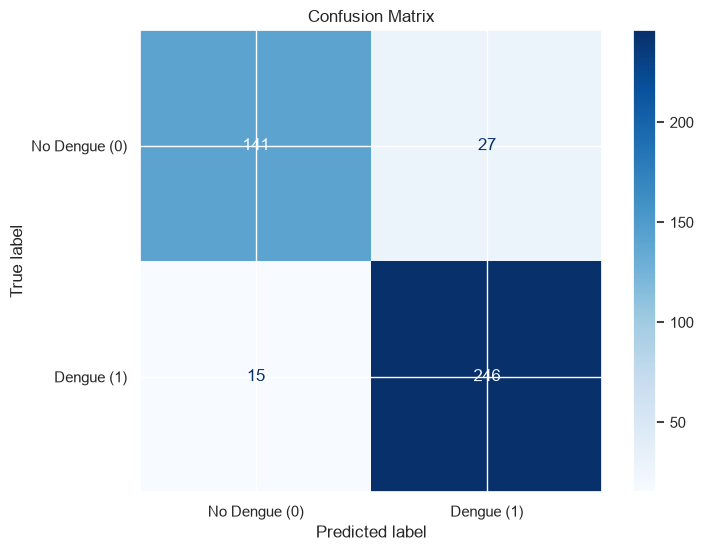

In [ ]:
cm = confusion_matrix(y_test, pred_test)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=['No Dengue (0)', 'Dengue (1)'])
fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Confusion Matrix')
plt.show()

<a name="4-Metricas"></a>
# Metricas


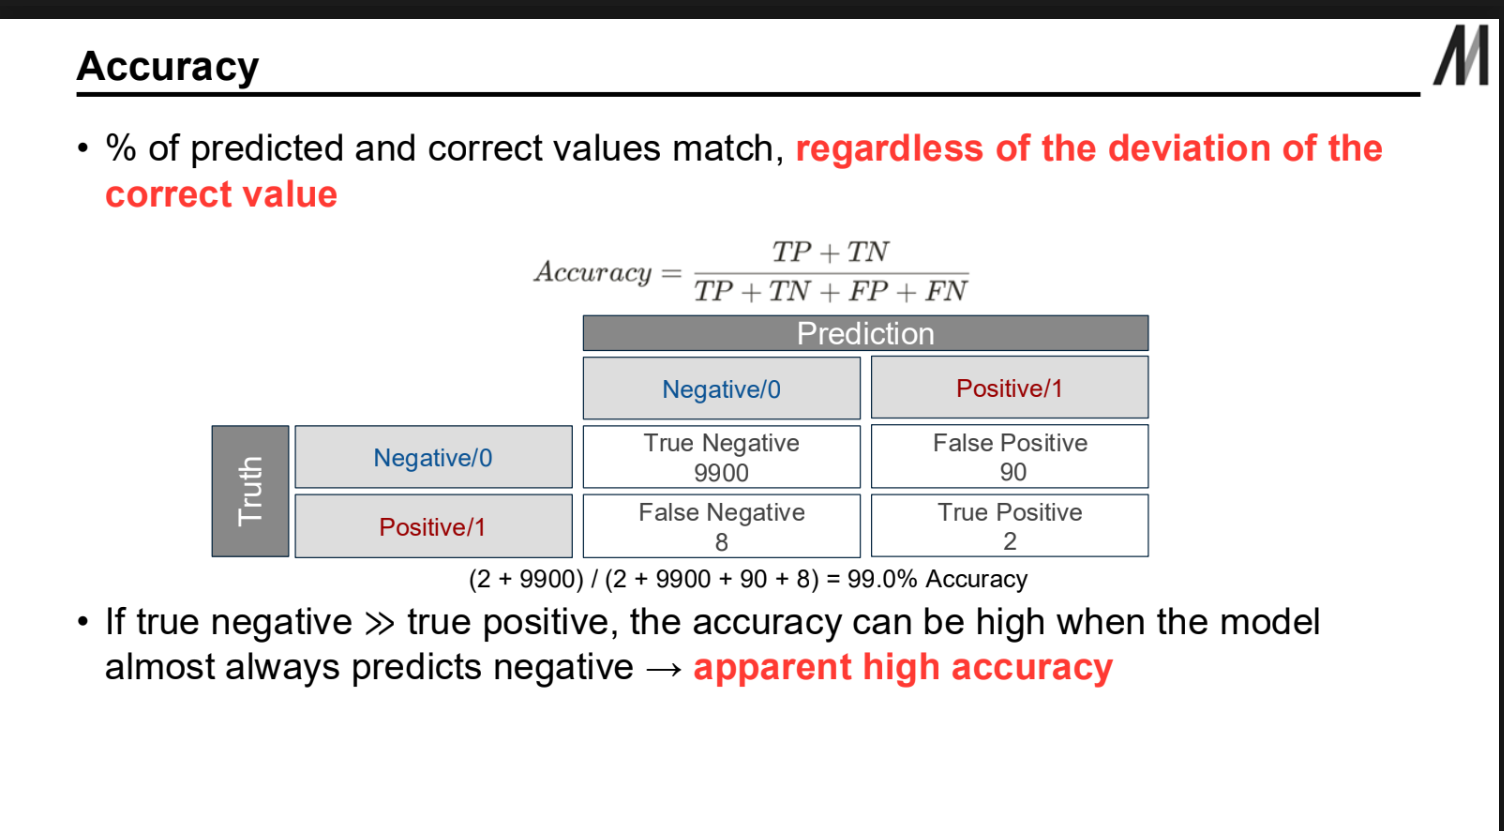

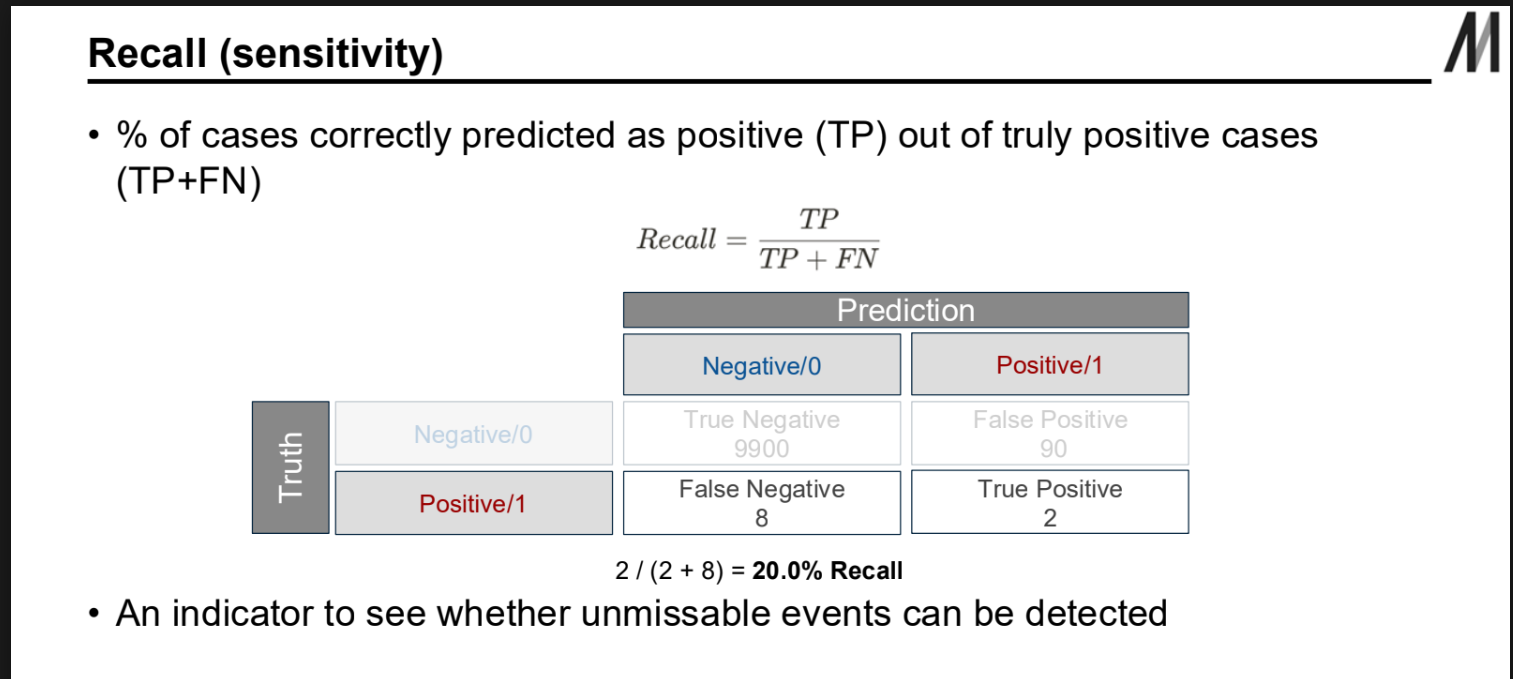

Conclusiones

<a name="6-No_Supervidado"></a>
#No Supervisado

In [ ]:
!pip install kmodes
from kmodes.kmodes import KModes
import matplotlib.pyplot as plt



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


#### Elbow

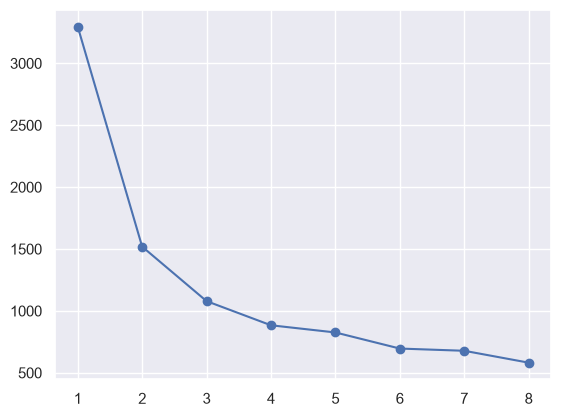

In [ ]:
binarias = [ 'Fever','Headache', 'Myalgia', 'Rash','Outcome']

costos=[]

rango_k=range(1,9)
for k in rango_k:
  km=KModes(n_clusters=k, n_init=5,init = "random", random_state=42)
  km.fit(df_dengue[binarias])
  costos.append(km.cost_)

plt.plot(rango_k,costos,marker='o')
plt.show()

In [ ]:
# Utilizando 3 clusters

modelKmode = KModes(n_clusters=3, init = "random", n_init = 5,random_state=42)
y_kmode = modelKmode.fit_predict(df_dengue[binarias])

# Costo
print('costo: ', modelKmode.cost_)

# Centroides
modasDf = pd.DataFrame(modelKmode.cluster_centroids_)
modasDf.columns = df_dengue[binarias].columns

print(modasDf)

# Cantidad por grupo
print(np.unique(y_kmode, return_counts=True))



costo:  1079.0
   Fever  Headache  Myalgia  Rash  Outcome
0      0         0        0     0        0
1      1         1        1     0        1
2      1         1        1     1        1
(array([0, 1, 2], dtype=uint16), array([622, 440, 653]))


In [ ]:
## Interpretacion de resultados ##

print('dataset original')

df_grouped = df_dengue.groupby(by=binarias)['Fever'].agg('count')
print(df_grouped)


print('\nclusterizacion por K-Modes')

df_dengue['cluster']= y_kmode
df=df_dengue[binarias+['cluster']]
# cluster 0
print(df[df.cluster==0].mode())

print('\n')

# cluster 1
print(df[df.cluster==1].mode())

print('\n')

# cluster 2
print(df[df.cluster==2].mode())


dataset original
Fever  Headache  Myalgia  Rash  Outcome
0      0         0        0     0          237
                          1     0           29
                 1        0     0           55
                          1     0           13
                                1            3
       1         0        0     0          105
                                1            4
                          1     0           21
                                1            5
                 1        0     0           26
                                1           12
                          1     0           14
                                1           10
1      0         0        0     0           40
                                1           19
                          1     0           16
                                1           33
                 1        0     0           18
                                1           53
                          1     0            7
   

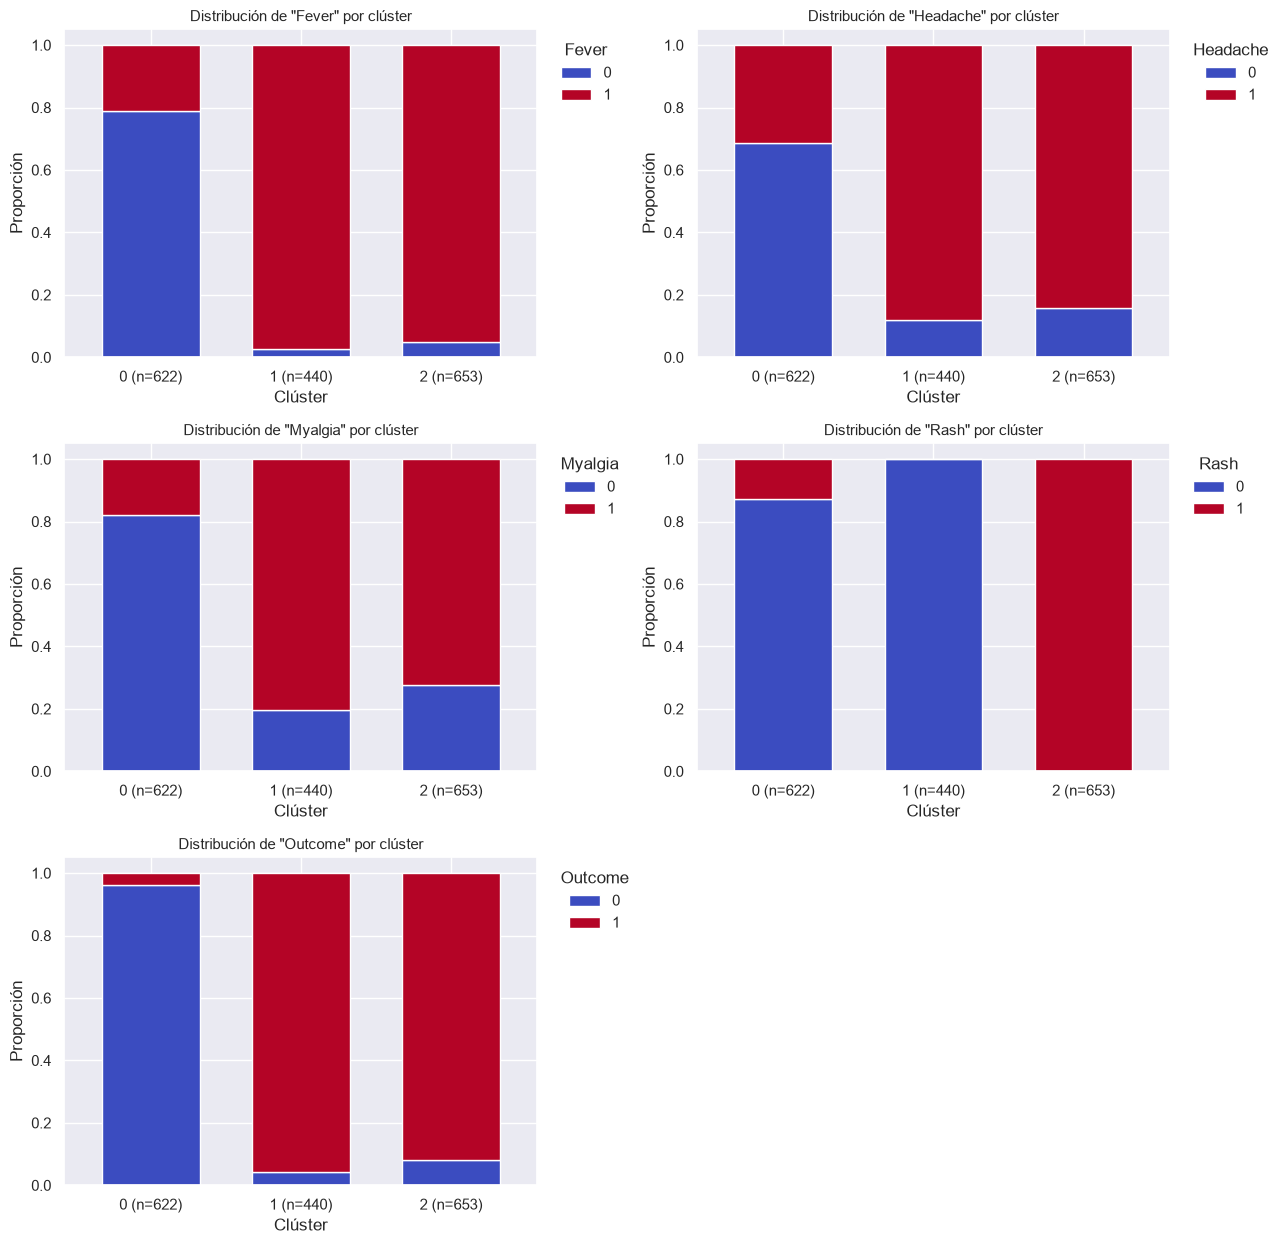

In [ ]:
import math
import matplotlib.pyplot as plt
import pandas as pd

# Variables categóricas a graficar (excluyendo 'cluster')
cat_cols = [col for col in df.columns if col != 'cluster']

#disposicion de los graficos
n_cols = 2
n_rows = math.ceil(len(cat_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols, figsize=(13, 4.2 * n_rows), squeeze=False
)
axes = axes.flatten()
etiquetas = {c: f"{c} (n={n})" for c, n in df['cluster'].value_counts().items()}

#cuantos hay
for i, col in enumerate(cat_cols):
  # Proporción (0 a 1) de cada categoría dentro de cada clúster

  ct = pd.crosstab(df['cluster'], df[col], normalize='index')
  ct.index = ct.index.map(etiquetas)
  ct.plot(kind='bar', stacked=True, ax=axes[i], colormap='coolwarm', width=0.65)

  axes[i].set_title(f'Distribución de "{col}" por clúster', fontsize=11)
  axes[i].set_xlabel('Clúster')
  axes[i].set_ylabel('Proporción')
  axes[i].set_ylim(0, 1.05)
  axes[i].tick_params(axis='x', rotation=0)
  axes[i].legend(
      title=col, bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False
  )


# Ocultar ejes sobrantes si la cantidad de variables es impar
for j in range(len(cat_cols), len(axes)):
  axes[j].set_visible(False)



plt.tight_layout()
plt.show()

#### Silhouette

El coeficiente de Silhouette para un punto i-ésimo es:

$S(i) = \frac{b(i)-a(i)}{max(a(i), b(i))}$

donde b(i) es la menor distancia promedio del punto i-ésimo a todos los demás puntos, a(i) es la distancia promedio del punto i-ésimo a los demás puntos en el cluster.

Consideraciones sobre el score:
*   Si S(i) es cercano a 1, el punto pertenece al cluster correcto
*   Si es cercano a -1, debería asignarese a otro cluster
*   Si es cercano a 0, está entre dos clusters

Como referencia general, si >0.7 estructura fuerte, 0.5-0.7 razonable, 0.25-0.5 débil, <0.25 prácticamente sin estructura.

In [ ]:
from sklearn.metrics import silhouette_samples

labels = y_kmode
sil_vals = silhouette_samples(X, labels, metric="hamming")

for c in np.unique(labels):
    print(f"Cluster {c}: silueta media = {sil_vals[labels == c].mean():.3f}")

Cluster 0: silueta media = 0.319
Cluster 1: silueta media = 0.659
Cluster 2: silueta media = 0.558


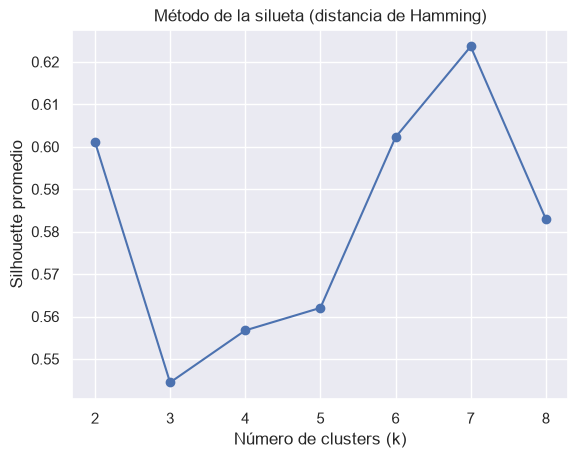

In [ ]:
from sklearn.metrics import silhouette_score
import numpy as np
import matplotlib.pyplot as plt
from kmodes.kmodes import KModes

X = df_dengue[binarias].values

rango_k = range(2, 9)   # la silueta requiere k >= 2
siluetas = []

for k in rango_k:
    km = KModes(n_clusters=k, init="random", n_init=5, random_state=42)
    labels = km.fit_predict(X)
    siluetas.append(silhouette_score(X, labels, metric="hamming"))

plt.plot(rango_k, siluetas, marker="o")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Silhouette promedio")
plt.title("Método de la silueta (distancia de Hamming)")
plt.show()

In [ ]:
for k in [3, 6, 7]:
    km = KModes(n_clusters=k, init="random", n_init=5, random_state=42)
    labels = km.fit_predict(X)
    sil = silhouette_samples(X, labels, metric="hamming")
    print(f"\nk={k}")
    for c in np.unique(labels):
        print(f"  Cluster {c}: n={np.sum(labels==c)}, silueta={sil[labels==c].mean():.3f}")
    print(pd.DataFrame(km.cluster_centroids_, columns=binarias))


k=3
  Cluster 0: n=622, silueta=0.501
  Cluster 1: n=440, silueta=0.651
  Cluster 2: n=653, silueta=0.514
   Fever  Headache  Myalgia  Rash  Outcome
0      0         0        0     0        0
1      1         1        1     0        1
2      1         1        1     1        1

k=6
  Cluster 0: n=169, silueta=0.150
  Cluster 1: n=402, silueta=0.839
  Cluster 2: n=477, silueta=0.536
  Cluster 3: n=234, silueta=0.464
  Cluster 4: n=301, silueta=0.864
  Cluster 5: n=132, silueta=0.349
   Fever  Headache  Myalgia  Rash  Outcome
0      1         0        1     1        1
1      1         1        1     1        1
2      0         0        0     0        0
3      1         1        0     1        1
4      1         1        1     0        1
5      1         0        0     0        0

k=7
  Cluster 0: n=521, silueta=0.448
  Cluster 1: n=301, silueta=0.861
  Cluster 2: n=103, silueta=0.554
  Cluster 3: n=90, silueta=0.548
  Cluster 4: n=254, silueta=0.360
  Cluster 5: n=388, silueta=0.914
  C

#### 3-Clusters
*   Cluster-1: Personas sin ningún síntoma y sin dengue.
*   Cluster-2: Personas con mayoría de síntomas y con dengue.
*   Cluster-3: Personas con todos los síntomas y con dengue.





<a name="4-Anexo"></a>
# Anexo
4.1 Union de datasets



In [ ]:
import os
import pandas as pd
PATH = '/content/gdrive/MyDrive/MCTD_TFI_PROYECTO/Datasets/dataset2026 (1).csv'
PATH2 = '/content/gdrive/MyDrive/MCTD_TFI_PROYECTO/Datasets/Dengue_clinical_dataset2025.csv'
df = pd.read_csv(PATH)
df2 = pd.read_csv(PATH2)
df2 = df2.rename(columns={'Duration_of_Fever': 'Fever_Duration', 'Platelet Count': 'Platelet_Count','WBC': 'WBC_Count', 'Muscle_Pain': 'Myalgia'})
print("\nDataset 2026\n")
print(df.shape)
print(df.info())

print("\nDataset 2025\n")
print(df2.shape)
print(df2.info())


Dataset 2026

(1000, 19)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Gender              1000 non-null   object 
 1   Age                 1000 non-null   int64  
 2   NS1                 1000 non-null   int64  
 3   IgG                 1000 non-null   int64  
 4   IgM                 1000 non-null   int64  
 5   Area                1000 non-null   object 
 6   AreaType            1000 non-null   object 
 7   HouseType           1000 non-null   object 
 8   District            1000 non-null   object 
 9   Fever_Duration      1000 non-null   int64  
 10  Body_Temperature    1000 non-null   float64
 11  Platelet_Count      1000 non-null   int64  
 12  WBC_Count           1000 non-null   int64  
 13  Joint_Pain          509 non-null    object 
 14  Headache            1000 non-null   int64  
 15  Retro_Orbital_Pain  1000 non-n

Variable Objetivo: Outcome.
Columna comunes: Gender, Age, Platelet_Count, WBC_Count, Headache, Myalgia, Rash, Fever Duration.

Columnas semanticamente similares: Fever y Body_Temperature

Columnas distintas:
Dataset 2026:
1. IgG, IgM, NS1.
2. Area, AreaType, HouseType, District.
3. Joint_Pain, Retro_Orbital_Pain.

Dataset 2025:
1. Location.
2. Vomiting


In [ ]:
df.head(n=5)

,Gender,Age,NS1,IgG,IgM,Area,AreaType,HouseType,District,Fever_Duration,Body_Temperature,Platelet_Count,WBC_Count,Joint_Pain,Headache,Retro_Orbital_Pain,Myalgia,Rash,Outcome
0,Female,45,0,0,0,Mirpur,Undeveloped,Building,Dhaka,2,36.9,278586,5806,Severe,0,0,1,0,0
1,Male,17,0,0,1,Chawkbazar,Developed,Building,Dhaka,1,36.5,190699,7690,NaN,1,0,0,0,0
2,Female,29,0,0,0,Paltan,Undeveloped,Other,Dhaka,1,36.6,208973,6928,NaN,0,0,0,0,0
3,Female,63,1,1,0,Motijheel,Developed,Other,Dhaka,7,38.9,94336,3193,Moderate,0,0,1,0,1
4,Male,22,0,0,0,Gendaria,Undeveloped,Building,Dhaka,1,37.0,288202,7768,NaN,0,0,0,0,0


In [ ]:
df2.head(n=5)

,Id,Gender,Age,Platelet_Count,WBC_Count,Location,Fever,Fever_Duration,Headache,Myalgia,Rash,Vomiting,Outcome
0,1,Male,16,149134,4468,Keraniganj,True,5,False,True,False,True,Positive
1,2,Female,25,85943,7050,Nagerhat,True,7,True,True,True,False,Positive
2,3,Female,32,285134,11000,Louhajang,False,0,False,True,True,True,Negative
3,4,Male,42,189911,7948,Louhajang,True,4,False,False,True,False,Negative
4,5,Female,16,108708,6070,Nagerhat,True,6,False,True,True,False,Positive


In [ ]:
df['Fever'] = df['Body_Temperature'] > 38
df.drop(columns='Body_Temperature', inplace=True)
df.drop(columns=['IgG','IgM','NS1','Area','AreaType','HouseType', 'District','Joint_Pain','Retro_Orbital_Pain'],inplace=True)

In [ ]:
df2.drop(columns=['Id','Location','Vomiting'],inplace=True)

Por qué source: Fever se definió distinto en cada fuente (en una es Body_Temperature > 38, en la otra viene directa). Si las poblaciones difieren, conviene saberlo.

In [ ]:
df['source']  = '2026'   # asigna el valor '2026' a todas las filas del primer dataset
df2['source'] = '2025'   # idem para el segundo

<a name="4.2-Concatenacion"></a>
## 4.2 Concatenacion


In [ ]:
df3 = pd.concat([df,df2], ignore_index=True)
df3.to_csv("/content/gdrive/MyDrive/MCTD_TFI_PROYECTO/dataset_combinado.csv", index=False)

print(df3.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2018 entries, 0 to 2017
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Gender          2018 non-null   object
 1   Age             2018 non-null   int64 
 2   Fever_Duration  2018 non-null   int64 
 3   Platelet_Count  2018 non-null   int64 
 4   WBC_Count       2018 non-null   int64 
 5   Headache        2018 non-null   int64 
 6   Myalgia         2018 non-null   int64 
 7   Rash            2018 non-null   int64 
 8   Outcome         2018 non-null   object
 9   Fever           2018 non-null   bool  
 10  source          2018 non-null   object
dtypes: bool(1), int64(7), object(3)
memory usage: 159.8+ KB
None
